In [8]:
import numpy as np
np.random.seed(42)

import pandas as pd

data = pd.read_csv("data/health_study_dataset.csv")

data.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [3]:
kolumner = ["age", "weight", "height", "systolic_bp", "cholesterol"]

statistik = data[kolumner].agg(["mean", "median", "min", "max"])

statistik.round(2)

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


I tabellen ovan ser vi att deltagarna är mellan 18 och 90 år. Medelåldern är ungefär 49 år och medianåldern är 50 år.

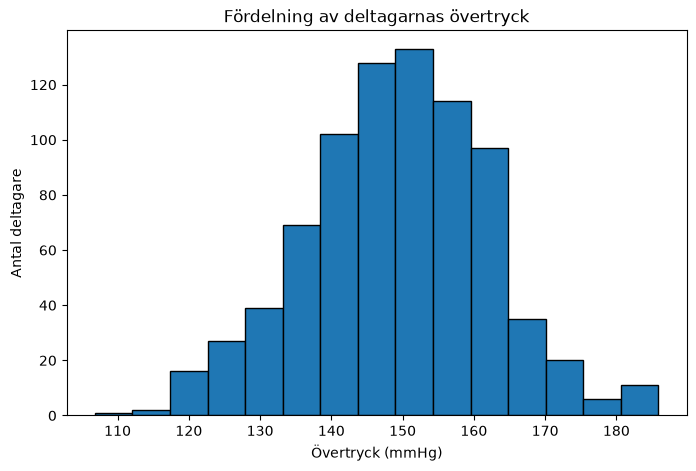

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(data["systolic_bp"], bins=15, edgecolor="black")

plt.title("Fördelning av deltagarnas övertryck")
plt.xlabel("Övertryck (mmHg)")
plt.ylabel("Antal deltagare")

plt.show()

Histogrammet ovan visar hur deltagarnas övertryck är fördelat. Den högsta stapeln ligger runt 150 mmHg, medan färre deltagare har värden ute vid diagrammets kanter.

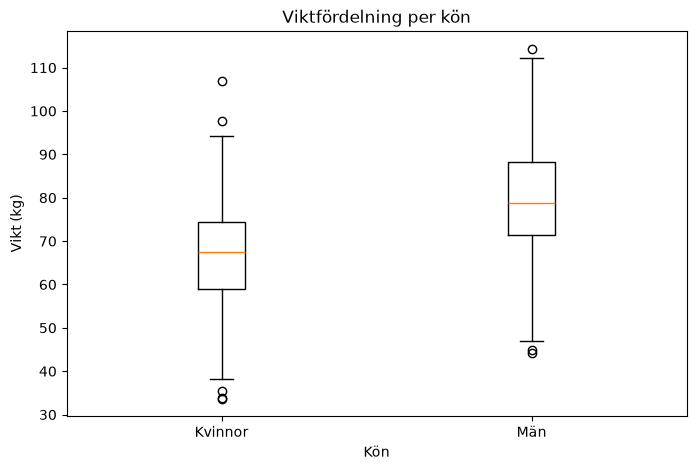

In [5]:
vikt_kvinnor = data.loc[data["sex"] == "F", "weight"]
vikt_man = data.loc[data["sex"] == "M", "weight"]

plt.figure(figsize=(8, 5))
plt.boxplot(
    [vikt_kvinnor, vikt_man],
    tick_labels=["Kvinnor", "Män"]
)

plt.title("Viktfördelning per kön")
plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")

plt.show()

I diagrammet ser vi att medianvikten är cirka 67 kg för kvinnor och 79 kg för män i datasetet. Den orange linjen i varje låda visar medianen.

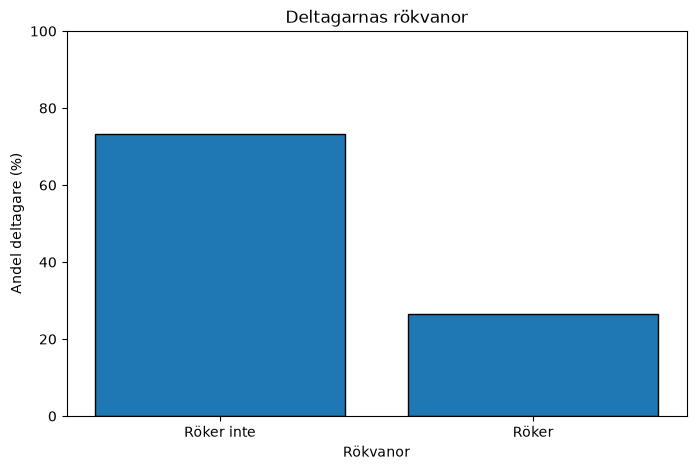

In [6]:
andelar = data["smoker"].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 5))

plt.bar(
    ["Röker inte", "Röker"],
    [andelar["No"], andelar["Yes"]],
    edgecolor="black"
)

plt.title("Deltagarnas rökvanor")
plt.xlabel("Rökvanor")
plt.ylabel("Andel deltagare (%)")
plt.ylim(0, 100)

plt.show()

Diagrammet visar deltagarnas rökvanor. Cirka 73 procent röker inte och 27 procent röker. Resultatet gäller både män och kvinnor tillsammans.

In [7]:
antal_deltagare = len(data)
antal_sjuka = (data["disease"] == 1).sum()

andel_sjuka = antal_sjuka / antal_deltagare

print("Antal deltagare:", antal_deltagare)
print("Antal med sjukdomen:", antal_sjuka)
print(f"Andel med sjukdomen: {andel_sjuka:.2%}")

Antal deltagare: 800
Antal med sjukdomen: 47
Andel med sjukdomen: 5.88%


In [9]:
simulerade_personer = np.random.binomial(
    n=1,
    p=andel_sjuka,
    size=1000
)

andel_simulerad = simulerade_personer.mean()

print(f"Andel i datasetet: {andel_sjuka:.2%}")
print(f"Andel i simuleringen: {andel_simulerad:.2%}")

Andel i datasetet: 5.88%
Andel i simuleringen: 5.60%
